In [1]:
import torch
import torch.nn as nn
import torchvision
import torch.optim as optim
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split
from torch.utils.data import Subset

import matplotlib.pyplot as plt
import numpy as np

import time
import os
import csv
import random


from models import ResNet_model, CNN_model

### $H(x)$
### $F(x) := H(x) - x$
### $H(x) := F(x) + x$

----

### $y = F(x, \{W_i\}) + x$
### $y = F(x, \{W_i\}) + W_sx$

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU


## Fetching Data

In [3]:
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)


train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])


test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])


train_augmented = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)

train_without_augmentation = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=test_transform
)

test_data = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=test_transform
)


generator = torch.Generator().manual_seed(42)
indices = torch.randperm(50000, generator=generator).tolist()


train_indices = indices[:45000]
val_indices = indices[45000:]


train_data = Subset(train_augmented, train_indices)
val_data = Subset(train_without_augmentation, val_indices)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(test_data))


Training images: 45000
Validation images: 5000
Test images: 10000


## TRAINING

In [4]:

def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predicted = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100.0 * correct / total
    epoch_error = 100.0 - epoch_accuracy

    return epoch_loss, epoch_accuracy, epoch_error


In [5]:

def evaluate(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predicted = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100.0 * correct / total
    epoch_error = 100.0 - epoch_accuracy

    return epoch_loss, epoch_accuracy, epoch_error


In [6]:

def set_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def initialize_weights(module):

    if isinstance(module, nn.Conv2d):
        nn.init.kaiming_normal_(
            module.weight,
            mode="fan_out",
            nonlinearity="relu"
        )

        if module.bias is not None:
            nn.init.zeros_(module.bias)

    elif isinstance(module, nn.BatchNorm2d):
        nn.init.ones_(module.weight)
        nn.init.zeros_(module.bias)


def run_experiment(
    model_name,
    n,
    history_writer,
    summary_writer,
    history_file,
    summary_file
):

    print("\n" + "=" * 60)
    print(f"Starting {model_name} | n={n}")
    print("=" * 60)

    set_seed(42)

    # Parameters
    batch_size = 128
    epochs = 100

    # DataLoaders
    train_generator = torch.Generator().manual_seed(42)

    train_loader = DataLoader(
        train_data,
        batch_size=batch_size,
        shuffle=True,
        num_workers=2,
        pin_memory=(device.type == "cuda"),
        generator=train_generator
    )

    val_loader = DataLoader(
        val_data,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=(device.type == "cuda")
    )

    test_loader = DataLoader(
        test_data,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=(device.type == "cuda")
    )

    # Create model
    if model_name == "CNN":
        model = CNN_model.CNN(n=n)

    elif model_name == "ResNet":
        model = ResNet_model.ResNet(n=n)

    else:
        raise ValueError("Unknown model name")

    model = model.to(device)
    model.apply(initialize_weights)

    # Loss function
    criterion = nn.CrossEntropyLoss()

    # Optimizer
    optimizer = optim.SGD(
        model.parameters(),
        lr=0.1,
        momentum=0.9,
        weight_decay=0.0001
    )

    # Learning rate scheduler
    scheduler = optim.lr_scheduler.MultiStepLR(
        optimizer,
        milestones=[50, 75],
        gamma=0.1
    )

    # Training loop
    for epoch in range(1, epochs + 1):

        train_loss, train_acc, train_error = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device
        )

        # Validation after every epoch
        val_loss, val_acc, val_error = evaluate(
            model,
            val_loader,
            criterion,
            device
        )

        current_lr = optimizer.param_groups[0]["lr"]

        # Save history
        history_writer.writerow({
            "model": model_name,
            "n": n,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "train_error": train_error,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "val_error": val_error,
            "lr": current_lr
        })

        history_file.flush()

        # Update learning rate
        scheduler.step()

        # Print progress every 5 epochs
        if epoch % 5 == 0 or epoch == 1:

            print(
                f"{model_name} | n={n} | "
                f"Epoch [{epoch}/{epochs}] | "
                f"Train Loss: {train_loss:.4f} | "
                f"Train Acc: {train_acc:.2f}% | "
                f"Val Loss: {val_loss:.4f} | "
                f"Val Acc: {val_acc:.2f}% | "
                f"LR: {current_lr}"
            )

    # Save trained model
    os.makedirs("results_100_epochs/models", exist_ok=True)

    model_path = f"results_100_epochs/models/{model_name}_n{n}.pth"
    torch.save(model.state_dict(), model_path)
	

    # Final evaluation on test dataset
    test_loss, test_acc, test_error = evaluate(
        model,
        test_loader,
        criterion,
        device
    )

    print("\nFINAL TEST RESULTS")
    print(f"Model: {model_name}, n={n}")
    print(f"Test Loss: {test_loss:.4f}")
    print(f"Test Accuracy: {test_acc:.2f}%")
    print(f"Test Error: {test_error:.2f}%")

    # Save final results
    summary_writer.writerow({
        "model": model_name,
        "n": n,
        "test_loss": test_loss,
        "test_accuracy": test_acc,
        "test_error": test_error
    })

    summary_file.flush()


In [8]:
results_dir = "results_100_epochs"
os.makedirs(results_dir, exist_ok=True)

history_path = os.path.join(results_dir, "history.csv")
summary_path = os.path.join(results_dir, "summary.csv")

history_columns = [
	"model",
	"n",
	"epoch",
	"train_loss",
	"train_accuracy",
	"train_error",
	"val_loss",
	"val_accuracy",
	"val_error",
	"lr"
]

summary_columns = [
	"model",
	"n",
	"test_loss",
	"test_accuracy",
	"test_error"
]

experiments = [
	("ResNet", 7)
]

# Append mode preserves results from previous runs
history_exists = (
	os.path.exists(history_path)
	and os.path.getsize(history_path) > 0
)

summary_exists = (
	os.path.exists(summary_path)
	and os.path.getsize(summary_path) > 0
)

with open(history_path, "a", newline="") as history_file, \
		open(summary_path, "a", newline="") as summary_file:

	history_writer = csv.DictWriter(
		history_file,
		fieldnames=history_columns
	)

	summary_writer = csv.DictWriter(
		summary_file,
		fieldnames=summary_columns
	)

	if not history_exists:
		history_writer.writeheader()

	if not summary_exists:
		summary_writer.writeheader()

	for model_name, n in experiments:

		run_experiment(
			model_name=model_name,
			n=n,
			history_writer=history_writer,
			summary_writer=summary_writer,
			history_file=history_file,
			summary_file=summary_file
		)

print("\nExperiment completed!")
print("Results saved in:", results_dir)


Starting ResNet | n=7
ResNet | n=7 | Epoch [1/100] | Train Loss: 2.2444 | Train Acc: 18.45% | Val Loss: 1.7674 | Val Acc: 32.88% | LR: 0.1
ResNet | n=7 | Epoch [5/100] | Train Loss: 0.8116 | Train Acc: 71.62% | Val Loss: 0.8482 | Val Acc: 70.34% | LR: 0.1
ResNet | n=7 | Epoch [10/100] | Train Loss: 0.5196 | Train Acc: 82.12% | Val Loss: 0.6292 | Val Acc: 78.80% | LR: 0.1
ResNet | n=7 | Epoch [15/100] | Train Loss: 0.4114 | Train Acc: 85.81% | Val Loss: 0.6374 | Val Acc: 79.32% | LR: 0.1
ResNet | n=7 | Epoch [20/100] | Train Loss: 0.3455 | Train Acc: 88.04% | Val Loss: 0.5947 | Val Acc: 80.40% | LR: 0.1
ResNet | n=7 | Epoch [25/100] | Train Loss: 0.3053 | Train Acc: 89.41% | Val Loss: 0.4396 | Val Acc: 85.74% | LR: 0.1
ResNet | n=7 | Epoch [30/100] | Train Loss: 0.2813 | Train Acc: 90.02% | Val Loss: 0.5885 | Val Acc: 81.80% | LR: 0.1
ResNet | n=7 | Epoch [35/100] | Train Loss: 0.2570 | Train Acc: 90.98% | Val Loss: 0.4108 | Val Acc: 86.86% | LR: 0.1
ResNet | n=7 | Epoch [40/100] | Tra


History CSV:
  Rows: 600

Summary CSV:
  Rows: 6
Saved: img/01_training_error_vs_depth.png
Saved: img/02_validation_error_vs_depth.png
Saved: img/03_test_error_vs_depth.png
Saved: img/04_training_loss_vs_epoch.png
Saved: img/05_validation_loss_vs_epoch.png
Saved: img/06_training_accuracy_vs_epoch.png
Saved: img/07_validation_accuracy_vs_epoch.png
Saved: img/08_test_accuracy_vs_depth.png

Final comparison (percentages except loss):
 model  n  depth train_accuracy val_accuracy test_accuracy test_error test_loss
   CNN  3     20          97.12        89.90         89.08      10.92    0.3943
ResNet  3     20          98.36        91.10         90.41       9.59    0.3662
   CNN  5     32          96.48        88.88         88.79      11.21    0.4288
ResNet  5     32          99.28        92.04         91.72       8.28    0.3353
   CNN  7     44          93.78        87.66         87.51      12.49    0.4203
ResNet  7     44          99.55        92.18         91.66       8.34    0.3654

Sav

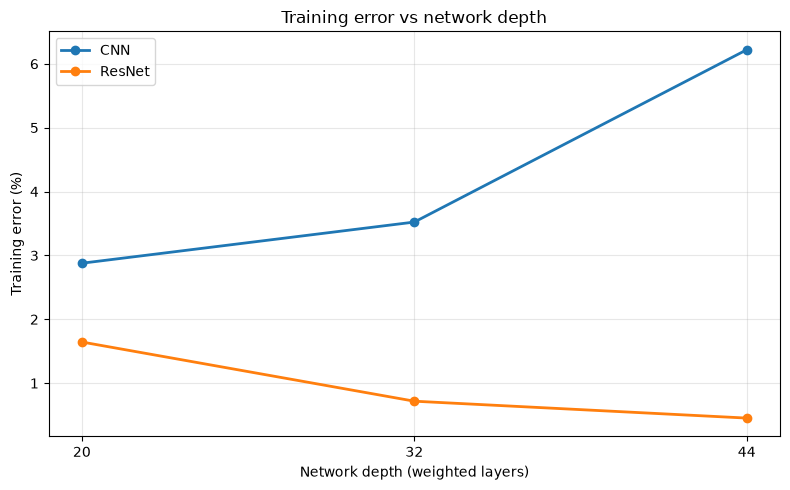

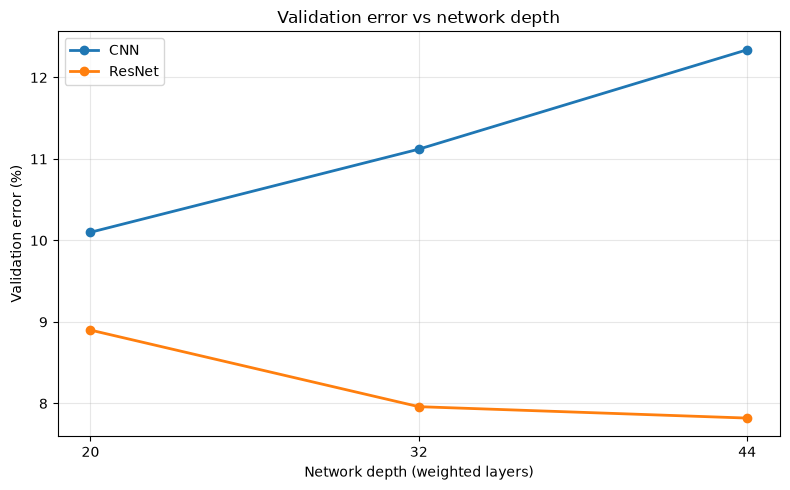

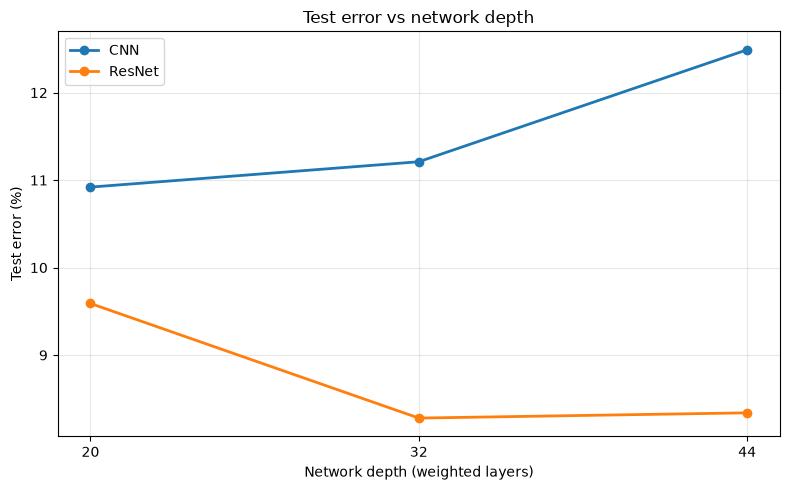

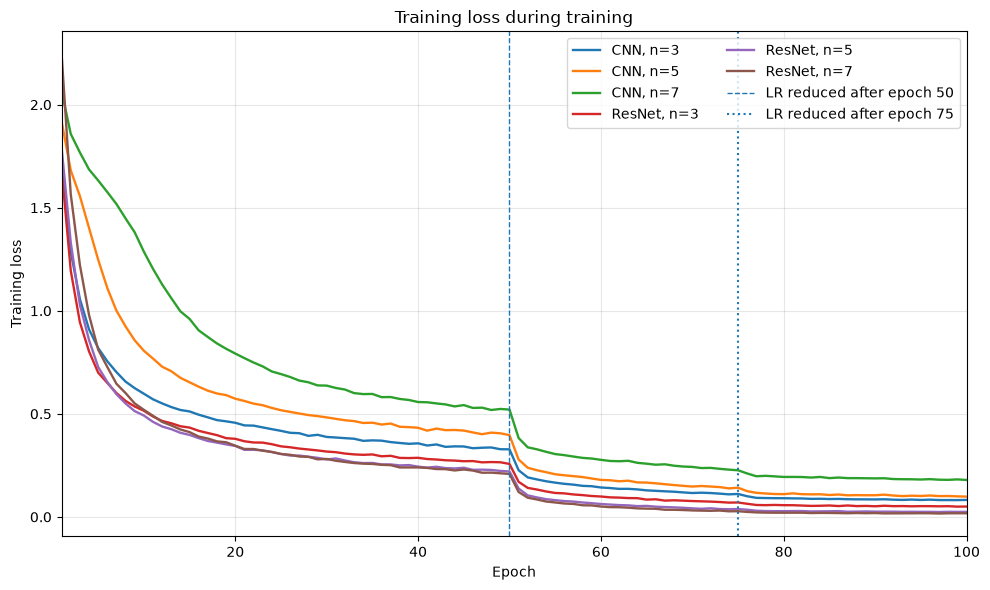

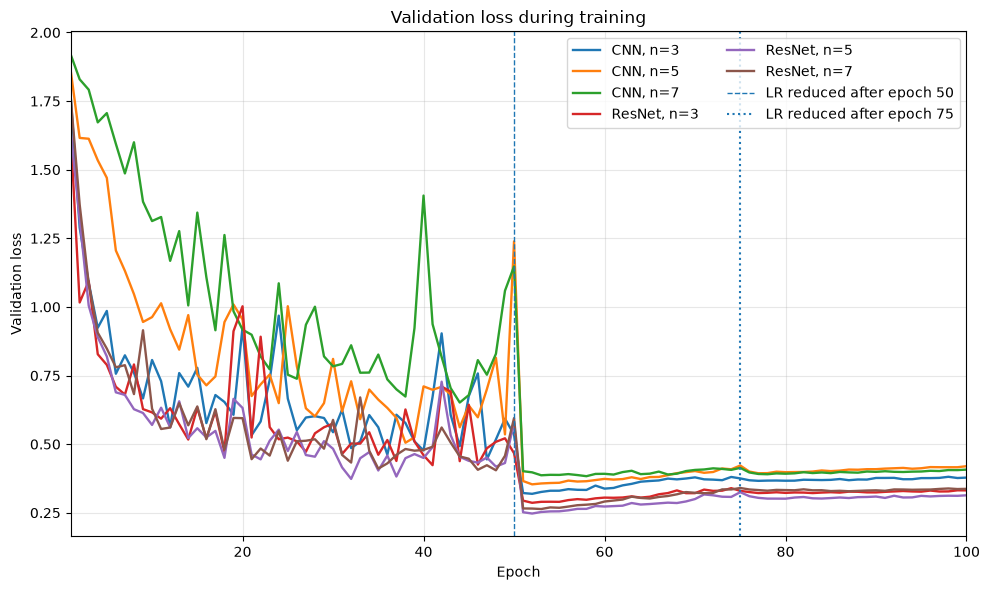

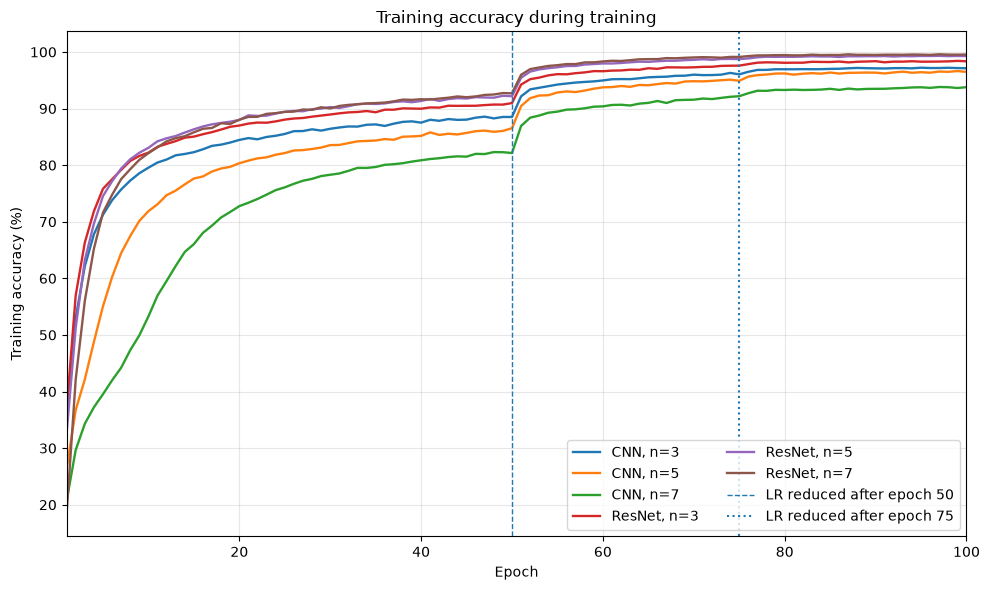

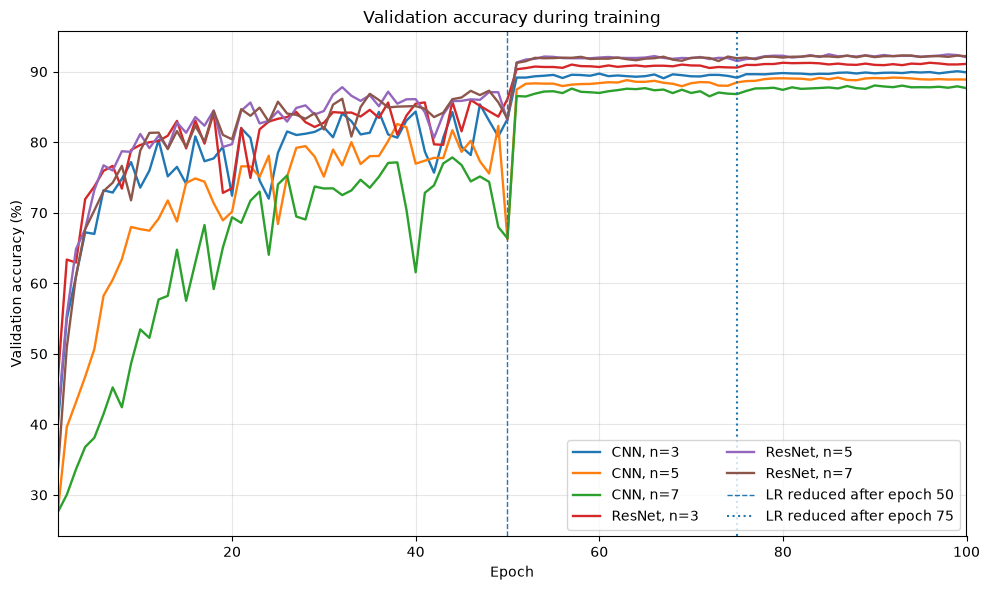

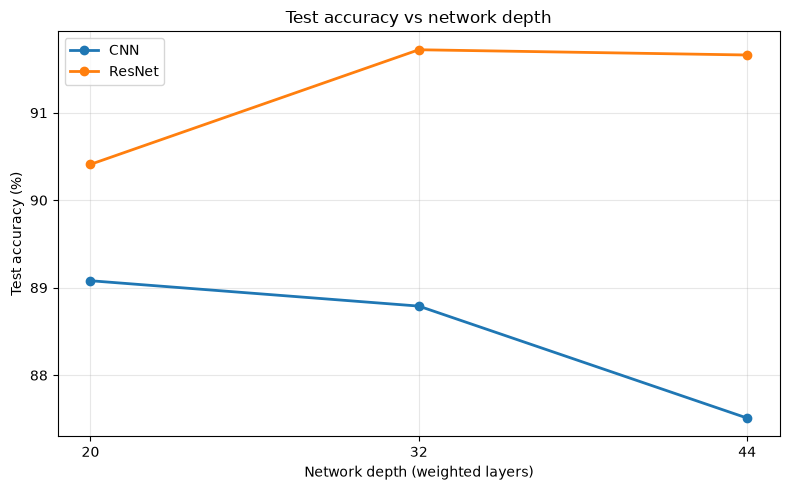

In [9]:
from plot import main

main(show_plots=True)